<a href="https://colab.research.google.com/github/Goat-Seller/bankruptcy-prediction/blob/main/bankruptcy_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Taiwanese companies bankrupcy prediction

#1 - data preparation

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme()

data = pd.read_csv('/content/data.csv')

In [ ]:
print(data.shape)
data.info()

(6819, 96)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Bankrupt?                                                 6819 non-null   int64  
 1    ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2    ROA(A) before interest and % after tax                   6819 non-null   float64
 3    ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4    Operating Gross Margin                                   6819 non-null   float64
 5    Realized Sales Gross Margin                              6819 non-null   float64
 6    Operating Profit Rate                                    6819 non-null   float64
 7    Pre-tax net Interest Rate                                6819 non-null   float64
 8    After-

In [ ]:
data.describe()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
count,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,...,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.0,6819.000000
mean,0.032263,0.505180,0.558625,0.553589,0.607948,0.607929,0.998755,0.797190,0.809084,0.303623,...,0.807760,1.862942e+07,0.623915,0.607946,0.840402,0.280365,0.027541,0.565358,1.0,0.047578
std,0.176710,0.060686,0.065620,0.061595,0.016934,0.016916,0.013010,0.012869,0.013601,0.011163,...,0.040332,3.764501e+08,0.012290,0.016934,0.014523,0.014463,0.015668,0.013214,0.0,0.050014
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000
25%,0.000000,0.476527,0.535543,0.527277,0.600445,0.600434,0.998969,0.797386,0.809312,0.303466,...,0.796750,9.036205e-04,0.623636,0.600443,0.840115,0.276944,0.026791,0.565158,1.0,0.024477
50%,0.000000,0.502706,0.559802,0.552278,0.605997,0.605976,0.999022,0.797464,0.809375,0.303525,...,0.810619,2.085213e-03,0.623879,0.605998,0.841179,0.278778,0.026808,0.565252,1.0,0.033798
75%,0.000000,0.535563,0.589157,0.584105,0.613914,0.613842,0.999095,0.797579,0.809469,0.303585,...,0.826455,5.269777e-03,0.624168,0.613913,0.842357,0.281449,0.026913,0.565725,1.0,0.052838
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,9.820000e+09,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.000000


In [ ]:
data.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


In [ ]:
print("Missing values:", data.isna().sum().sum())
print("Duplicated rows:", data.duplicated().sum())

Missing values: 0
Duplicated rows: 0


# 2 - Data visualisation


In [ ]:
target = "Bankrupt?"

constant = [c for c in data.columns if data[c].nunique() == 1]
binary = [c for c in data.columns if data[c].nunique() <= 2 and c != target]


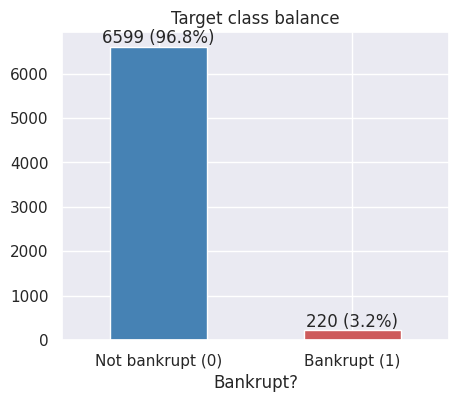

In [ ]:
data.columns = data.columns.str.strip()

fig, ax = plt.subplots(figsize=(5, 4))
counts = data[target].value_counts().sort_index()
counts.plot.bar(ax=ax, color=["steelblue", "indianred"])
ax.set_xticklabels(["Not bankrupt (0)", "Bankrupt (1)"], rotation=0)
for i, v in enumerate(counts):
    ax.text(i, v, f"{v} ({v / len(data):.1%})", ha="center", va="bottom")
ax.set_title("Target class balance")
plt.show()

# Features correlation

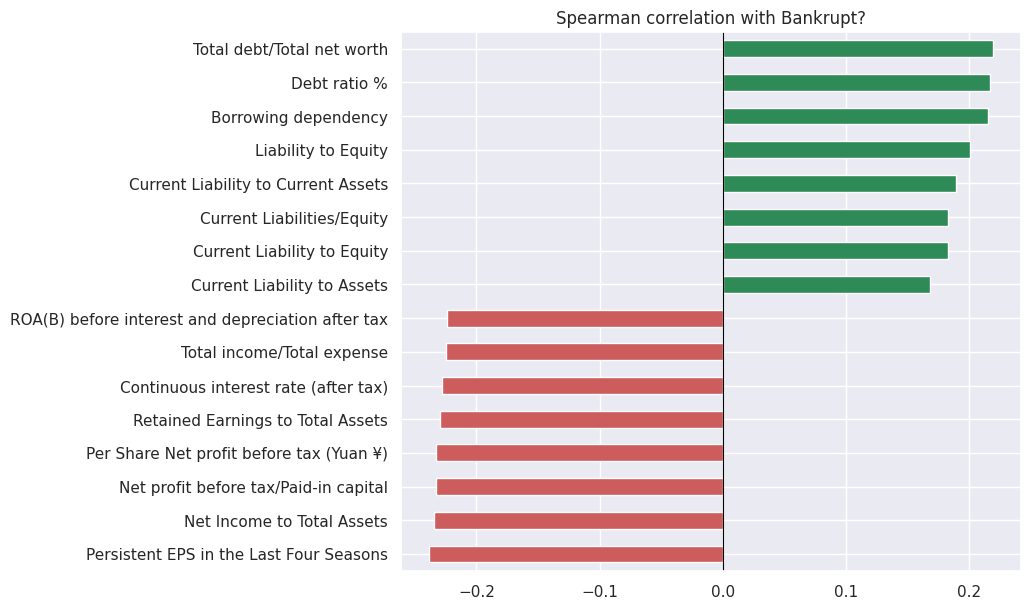

In [ ]:
features = [c for c in data.columns if c != target and c not in constant]
corr_t = data[features].corrwith(data[target], method="spearman").sort_values()

top = pd.concat([corr_t.head(8), corr_t.tail(8)])

plt.figure(figsize=(8, 7))
top.plot.barh(color=["indianred" if v < 0 else "seagreen" for v in top])
plt.axvline(0, color="black", lw=0.8)
plt.title("Spearman correlation with Bankrupt?")
plt.show()


In [ ]:
print(corr_t.abs().sort_values(ascending=False).head(20))

Persistent EPS in the Last Four Seasons                    0.238209
Net Income to Total Assets                                 0.234316
Net profit before tax/Paid-in capital                      0.233106
Per Share Net profit before tax (Yuan ¥)                   0.232442
Retained Earnings to Total Assets                          0.229533
Continuous interest rate (after tax)                       0.227621
Total income/Total expense                                 0.224564
ROA(B) before interest and depreciation after tax          0.224163
ROA(C) before interest and depreciation before interest    0.223589
ROA(A) before interest and % after tax                     0.222410
After-tax net Interest Rate                                0.220308
Pre-tax net Interest Rate                                  0.219694
Total debt/Total net worth                                 0.219323
Net Income to Stockholder's Equity                         0.219057
Debt ratio %                                    

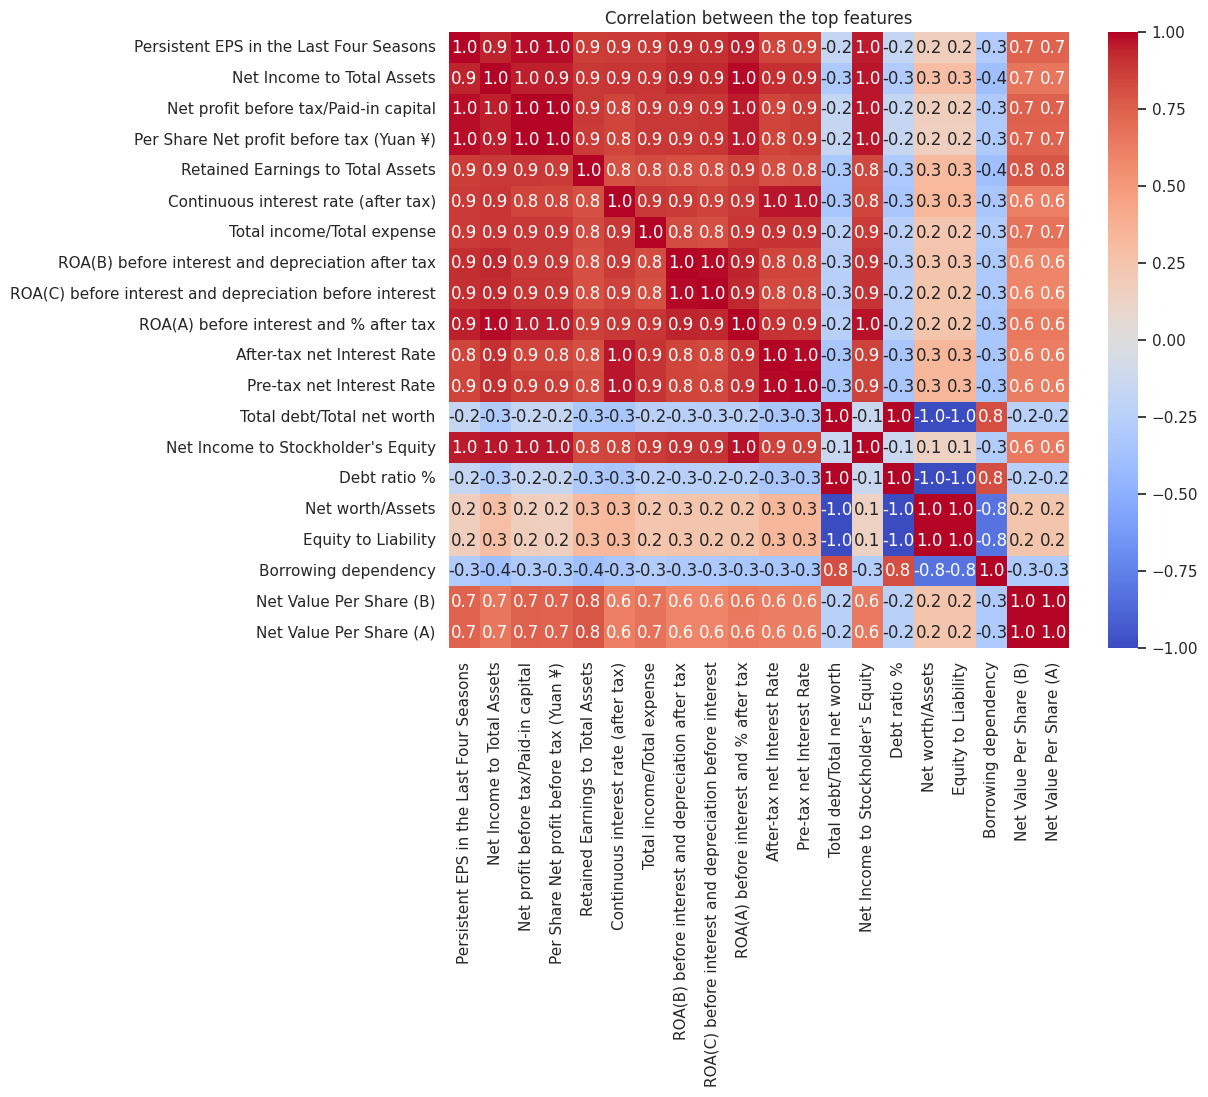

In [ ]:
top20 = corr_t.abs().sort_values(ascending=False).head(20).index.tolist()

cm = data[top20].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between the top features")
plt.show()

The top 12 highest correlated features with bankrupty are also highly correlated with eachother. Therefore only one feature from this group is suficcient:


- Persistent EPS in the Last Four Seasons

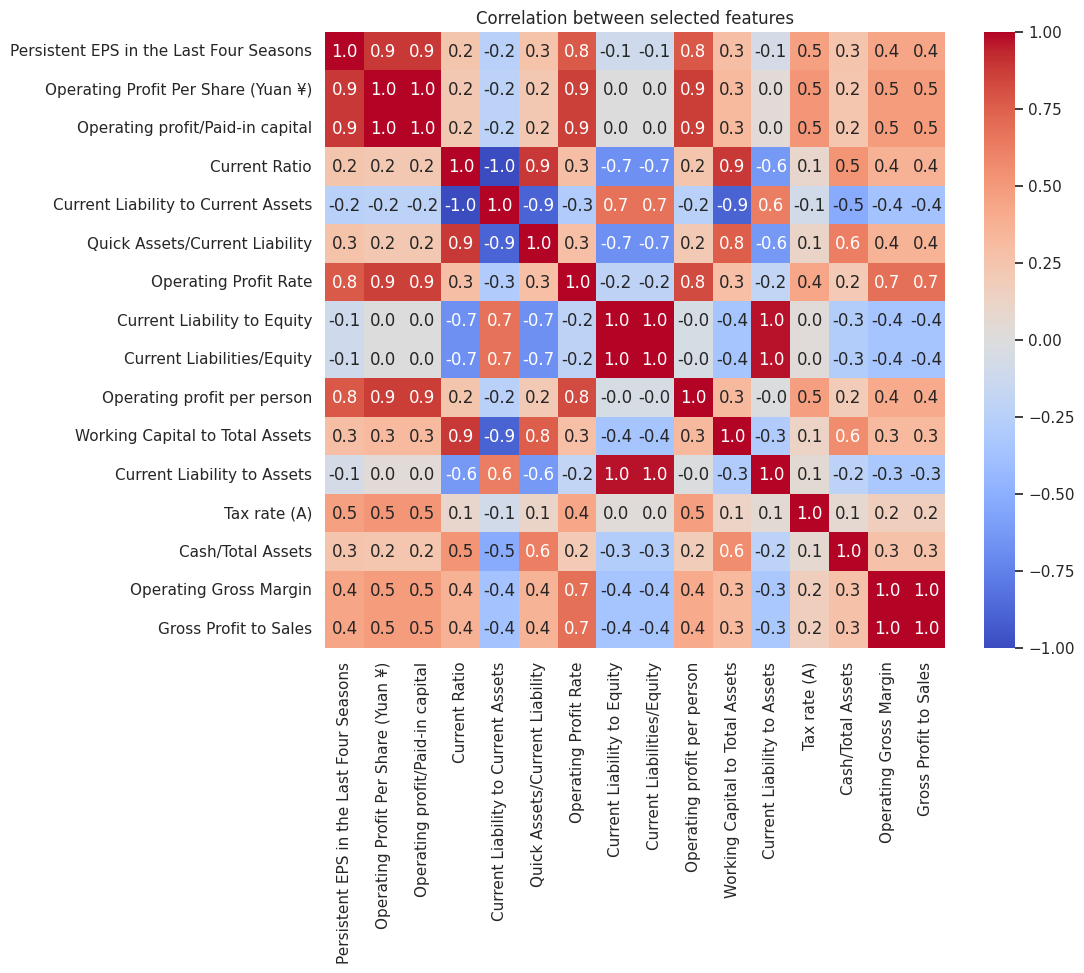

In [ ]:
topN = corr_t.abs().sort_values(ascending=False).head(40).index.tolist()

sel = [topN[0]] + topN[25:]      # Persistent EPS + cechy od 13. do końca

cm = data[sel].corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between selected features")
plt.show()

- Total debt/Total networth
- x debt ratio - highly correlated with total debt
- x Net worth/Assets - highly correlated with total debt
- x Equity to liability
- Borrowing dependency - very high but ok
- net value per share (A) - high but ok
- Non-idustry income and expenditure/revenue - very good
- Quick ratio - ok


#Choosing the most important features

features have to be correlated with target and not be correlated with each other.

There are too many features, the code below choses the best features automatically

In [ ]:
features = [c for c in data.columns if c != target and c not in constant]
corr_t = data[features].corrwith(data[target], method="spearman")
corr_f = data[features].corr(method="spearman").abs()

chosen = []
for c in corr_t.abs().sort_values(ascending=False).index:
    if all(corr_f.loc[c, s] < 0.7 for s in chosen):
        chosen.append(c)
    if len(chosen) == 10:
        break

print(corr_t[chosen].round(3))
print("\n\n\nChosen features count : ", corr_t[chosen].size)

Persistent EPS in the Last Four Seasons       -0.238
Total debt/Total net worth                     0.219
Non-industry income and expenditure/revenue   -0.205
Net Value Growth Rate                         -0.203
Quick Ratio                                   -0.202
Tax rate (A)                                  -0.158
Cash/Total Assets                             -0.151
Operating Gross Margin                        -0.148
Degree of Financial Leverage (DFL)            -0.147
Operating Funds to Liability                  -0.145
dtype: float64



Chosen features count :  10


# Plotting the chosen features correlation heatmap

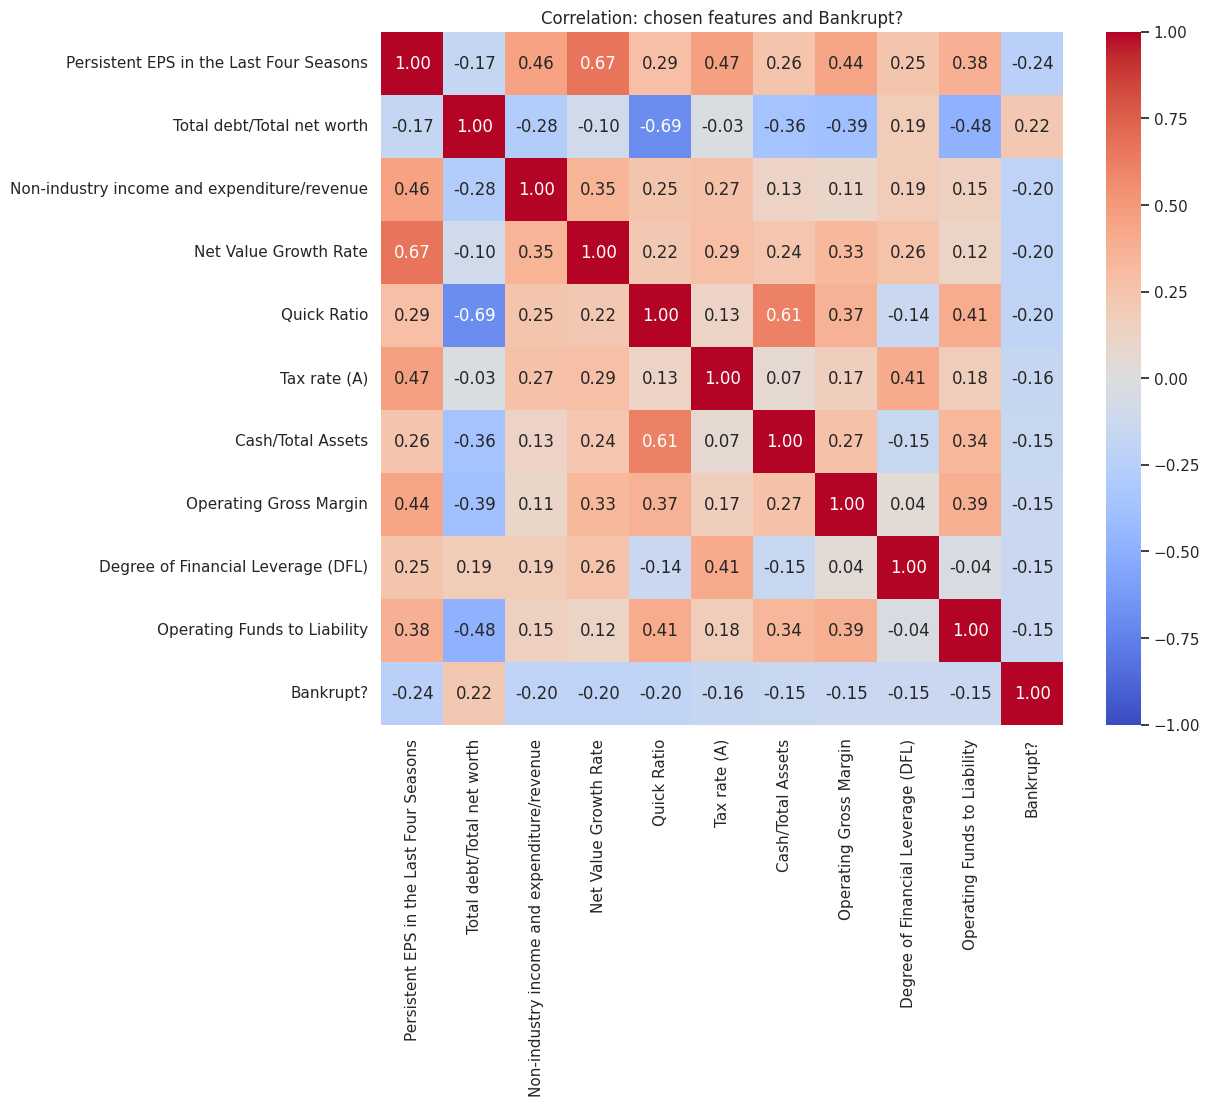

In [ ]:
cm = data[chosen + [target]].corr(method="spearman")

plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation: chosen features and Bankrupt?")
plt.show()

# chosen features charts

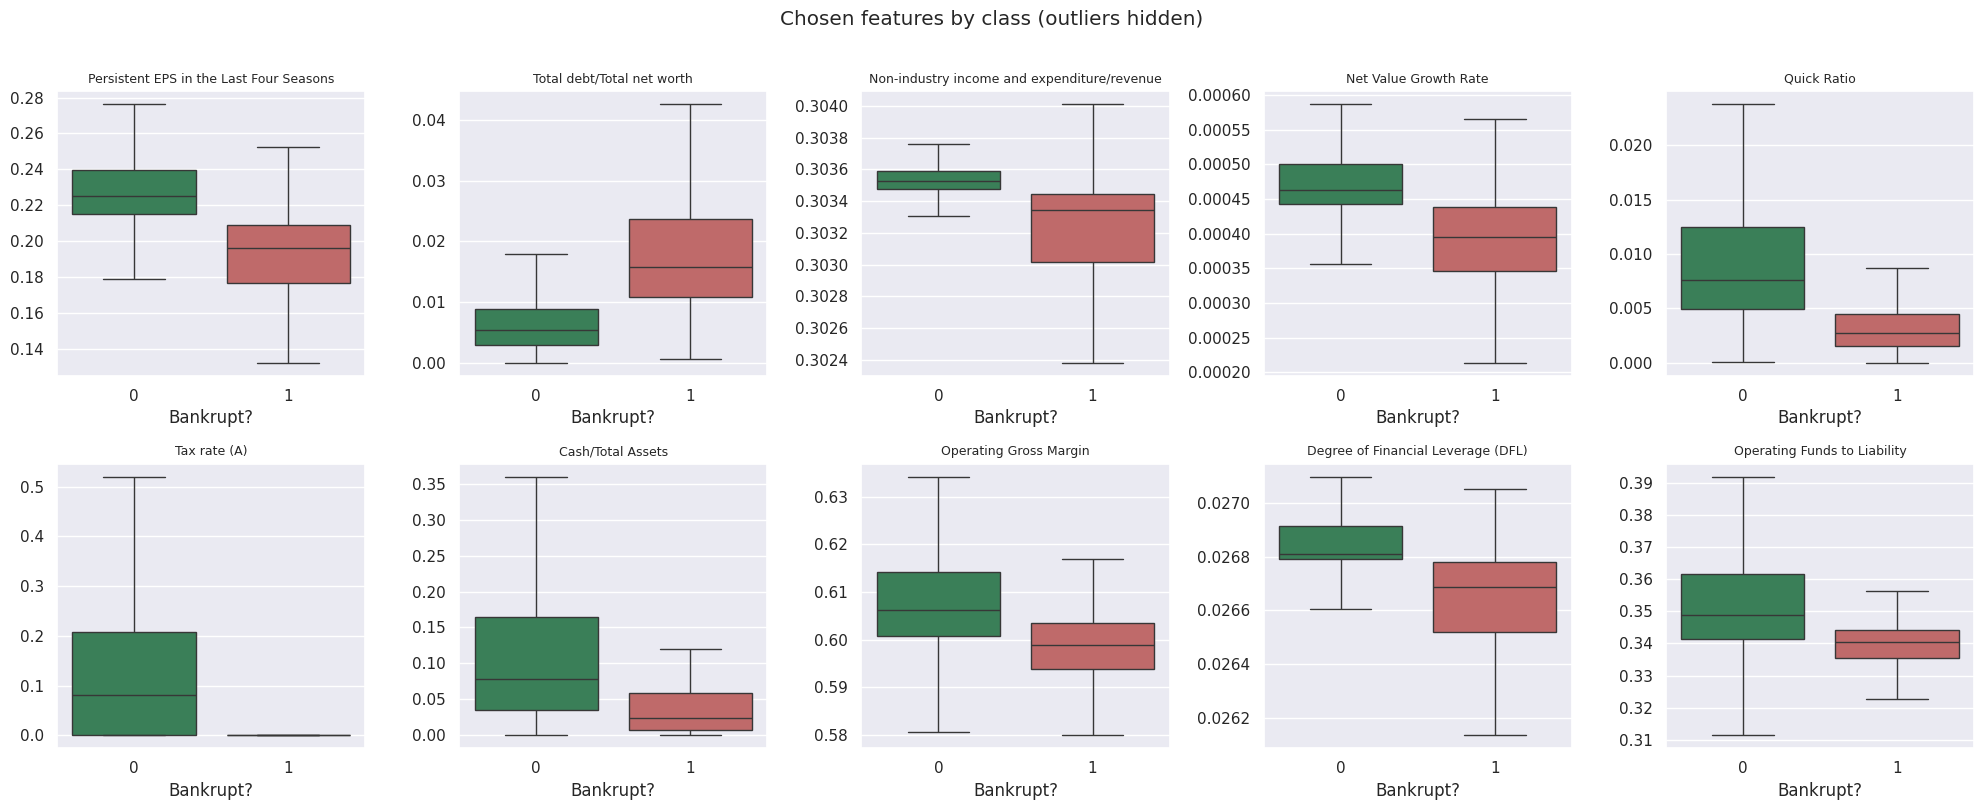

In [ ]:
palette = {0: "seagreen", 1: "indianred"}

fig, ax = plt.subplots(2, 5, figsize=(20, 8))
ax = ax.flatten()
for a, c in zip(ax, chosen):
    sns.boxplot(data=data, x=target, y=c, hue=target, palette=palette,
                legend=False, ax=a, showfliers=False)
    a.set_title(c, fontsize=9)
    a.set_xlabel("Bankrupt?")
    a.set_ylabel("")
plt.suptitle("Chosen features by class (outliers hidden)", y=1.01)
plt.tight_layout()
plt.show()

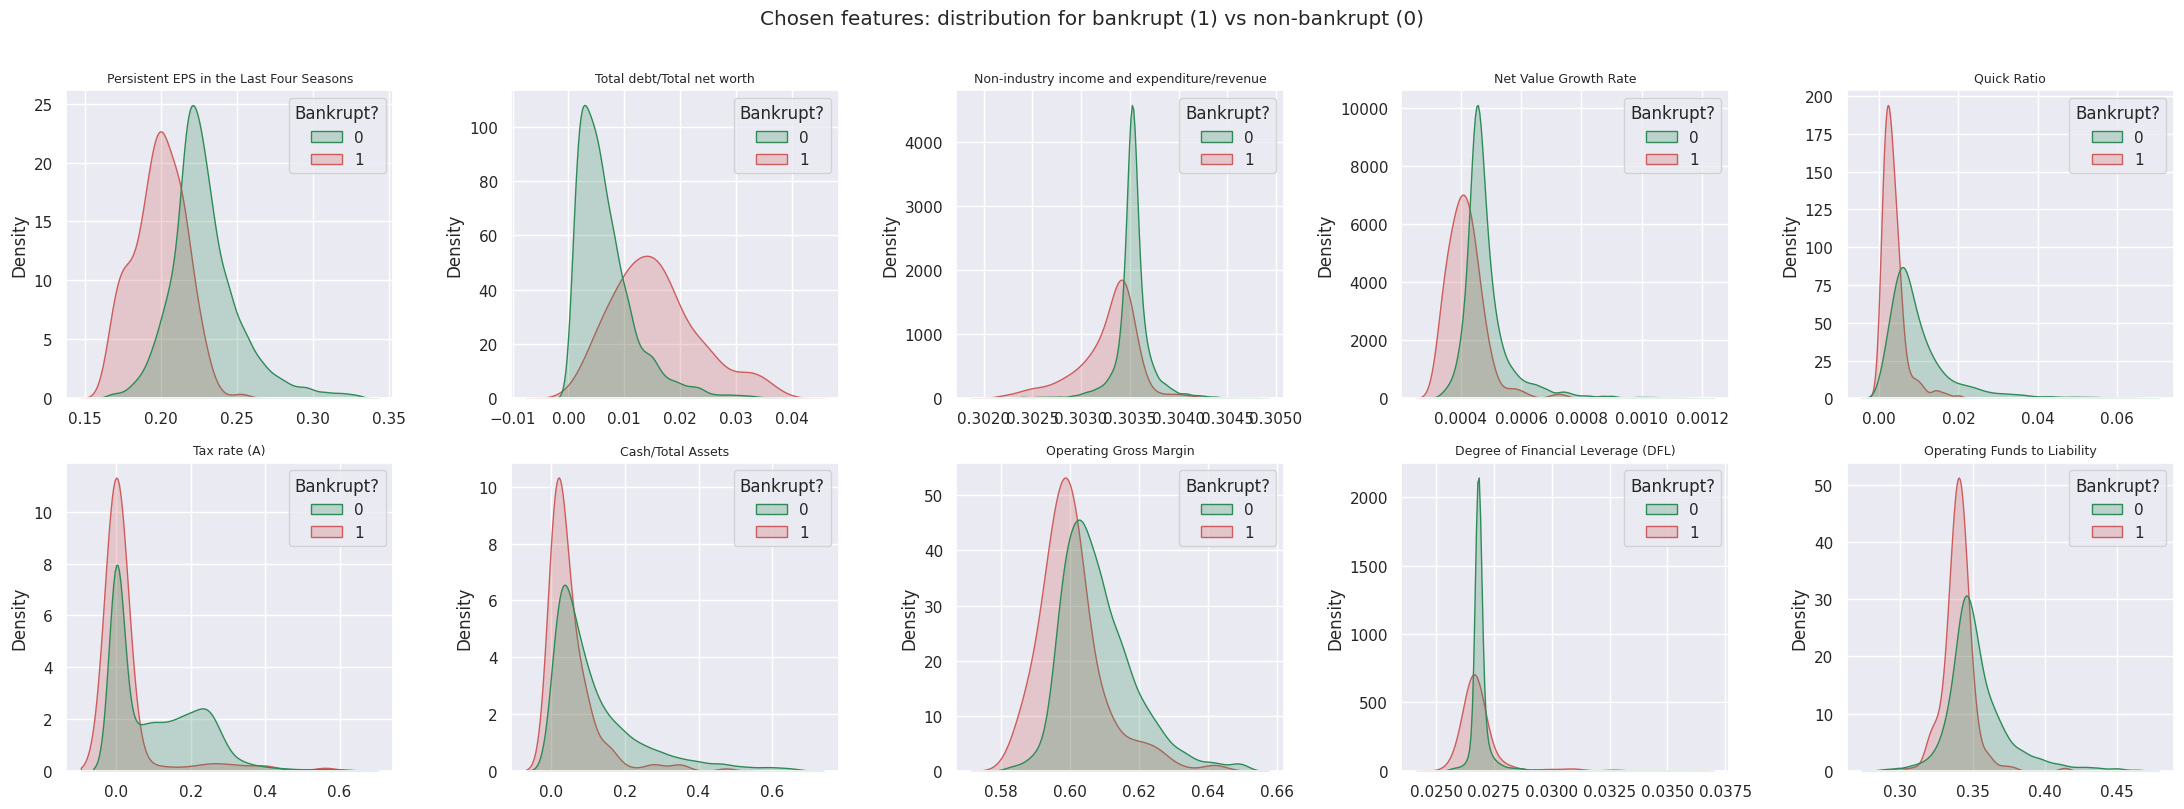

In [ ]:
palette = {0: "seagreen", 1: "indianred"}

fig, ax = plt.subplots(2, 5, figsize=(22, 8))
ax = ax.flatten()
for a, c in zip(ax, chosen):
    lo, hi = data[c].quantile([0.01, 0.99])
    sub = data[(data[c] >= lo) & (data[c] <= hi)]          # without outliers
    sns.kdeplot(data=sub, x=c, hue=target, common_norm=False,
                fill=True, palette=palette, ax=a, warn_singular=False)
    a.set_title(c, fontsize=9)
    a.set_xlabel("")
plt.suptitle("Chosen features: distribution for bankrupt (1) vs non-bankrupt (0)", y=1.01)
plt.tight_layout()
plt.show()

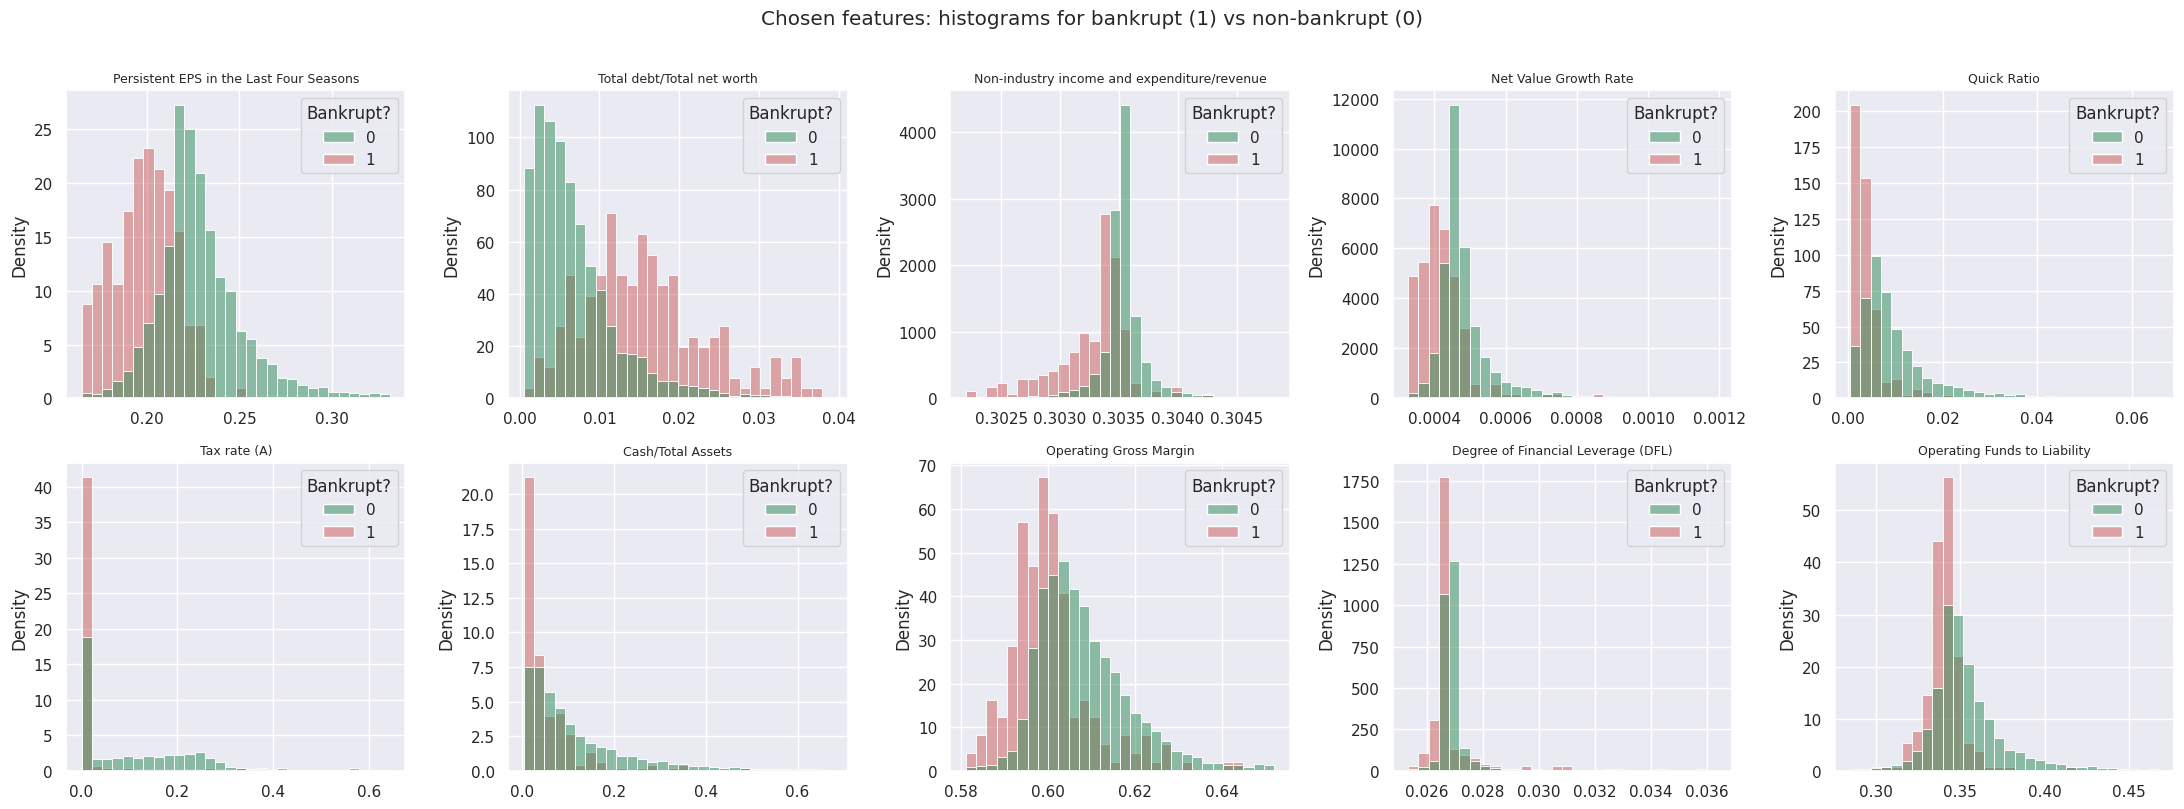

In [ ]:
palette = {0: "seagreen", 1: "indianred"}

fig, ax = plt.subplots(2, 5, figsize=(22, 8))
ax = ax.flatten()
for a, c in zip(ax, chosen):
    lo, hi = data[c].quantile([0.01, 0.99])
    sub = data[(data[c] >= lo) & (data[c] <= hi)]
    sns.histplot(data=sub, x=c, hue=target, bins=30, stat="density",
                 common_norm=False, common_bins=True, palette=palette,
                 alpha=0.5, ax=a)
    a.set_title(c, fontsize=9)
    a.set_xlabel("")
plt.suptitle("Chosen features: histograms for bankrupt (1) vs non-bankrupt (0)", y=1.01)
plt.tight_layout()
plt.show()

Checking for any potential data issues:

Infinite values per chosen feature:
None

NaN values per chosen feature:
None

Data types of chosen features:
Persistent EPS in the Last Four Seasons        float64
Total debt/Total net worth                     float64
Non-industry income and expenditure/revenue    float64
Net Value Growth Rate                          float64
Quick Ratio                                    float64
Tax rate (A)                                   float64
Cash/Total Assets                              float64
Operating Gross Margin                         float64
Degree of Financial Leverage (DFL)             float64
Operating Funds to Liability                   float64
dtype: object

Unique target values: [1 0] (Should be [0, 1] or [1, 0])
